# Task 1: Multi-Class Benchmark Classification Pipeline (Iris)

**Goal:** Build an end-to-end supervised classification pipeline on the Iris dataset.

**Pipeline steps**
1. Load the dataset with Pandas
2. Exploratory analysis with Seaborn pairplots
3. Train/test split (80/20) and feature scaling with `StandardScaler`
4. Train Logistic Regression and Decision Tree models
5. Benchmark accuracy, precision, recall and F1-score
6. Confusion matrix heatmaps
7. Decision boundary visualization

**Tools:** Python, Pandas, Scikit-Learn, Seaborn, Matplotlib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load the dataset with Pandas

The data is read from `data/iris.csv` the Iris file contains: 150 samples, 4 numeric features and the `species` label

In [ ]:
from pathlib import Path

DATA_PATH = Path("data/iris.csv")

df = pd.read_csv(DATA_PATH)

# numeric class label derived from the species name (alphabetical order)
class_names = sorted(df["species"].unique())
df["target"] = df["species"].map({name: i for i, name in enumerate(class_names)})
feature_cols = [c for c in df.columns if c not in ("species", "target")]

print("Shape:", df.shape)
display(df.head())
display(df.describe().round(2))
print("\nClass distribution:")
print(df["species"].value_counts())
print("\nMissing values:", int(df.isna().sum().sum()))

## 2. Exploratory analysis: pairplot

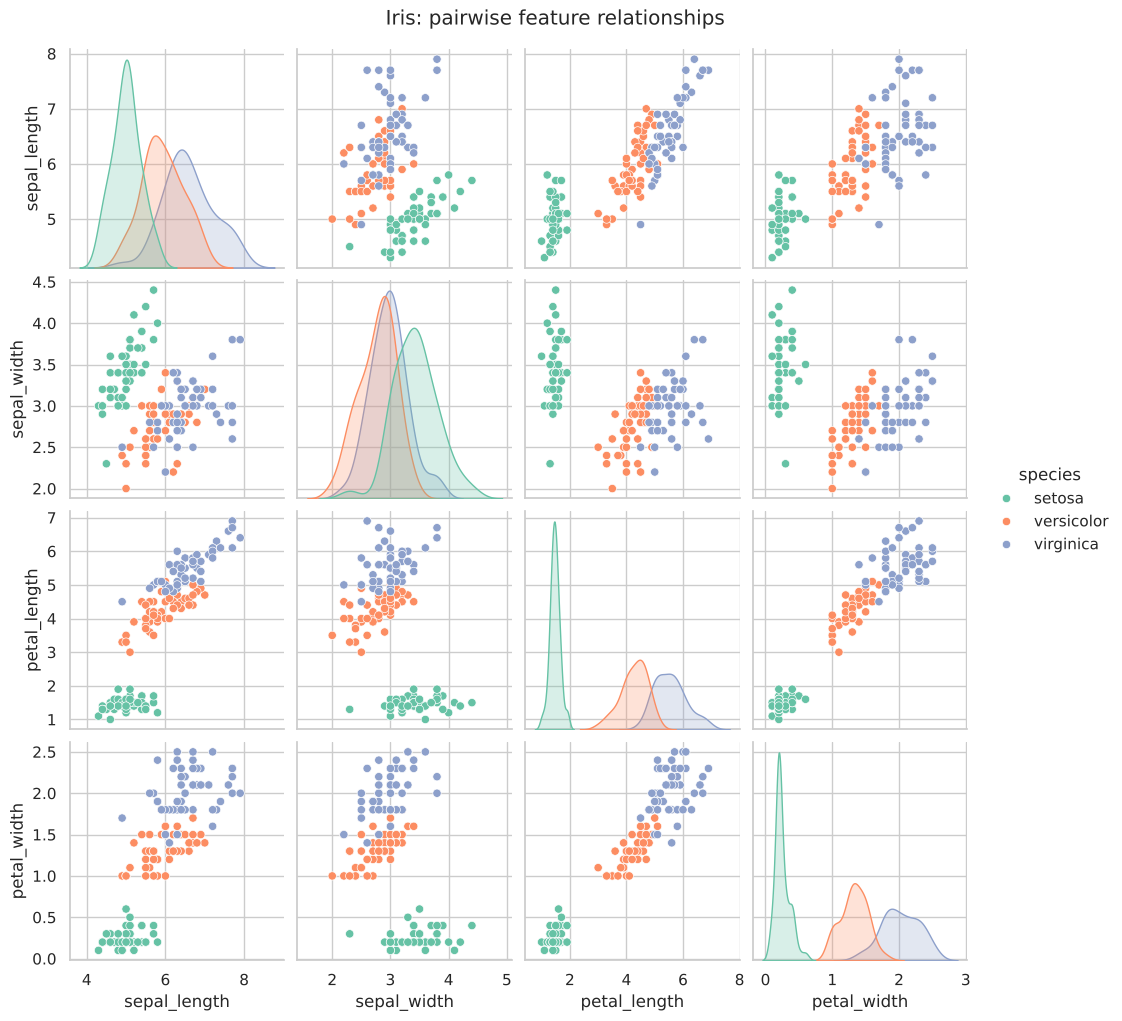

In [3]:
g = sns.pairplot(df, vars=feature_cols, hue="species", diag_kind="kde", palette="Set2")
g.fig.suptitle("Iris: pairwise feature relationships", y=1.02)
plt.show()

**Observation:** *setosa* is clearly separable from the other two classes, especially along petal length and petal width. *versicolor* and *virginica* overlap slightly, so that is where the models are most likely to make mistakes.

## 3. Train/test split (80/20) and feature scaling

The split is stratified so every class keeps the same proportion. The scaler is **fit on the training data only** to avoid data leakage.

In [4]:
X = df[feature_cols]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
print("Scaled train mean (approx. 0):", X_train_scaled.mean(axis=0).round(2))
print("Scaled train std  (approx. 1):", X_train_scaled.std(axis=0).round(2))

Train: 120 samples | Test: 30 samples
Scaled train mean (approx. 0): [-0.  0.  0.  0.]
Scaled train std  (approx. 1): [1. 1. 1. 1.]


## 4. Train the models

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree


## 5. Benchmark: accuracy, precision, recall, F1-score

Precision, recall and F1 use **macro averaging** (each class counts equally).

In [6]:
rows = []
for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
display(results)

for name, y_pred in predictions.items():
    print(f"\n=== Classification report: {name} ===")
    print(classification_report(y_test, y_pred, target_names=class_names))

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666



=== Classification report: Logistic Regression ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


=== Classification report: Decision Tree ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



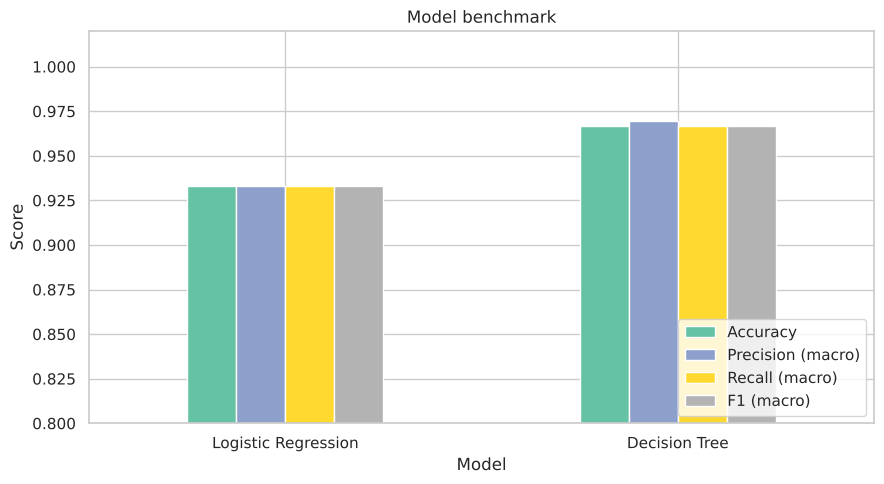

In [7]:
ax = results.plot(kind="bar", figsize=(9, 5), rot=0, colormap="Set2")
ax.set_ylim(0.8, 1.02)
ax.set_title("Model benchmark")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Confusion matrix heatmaps

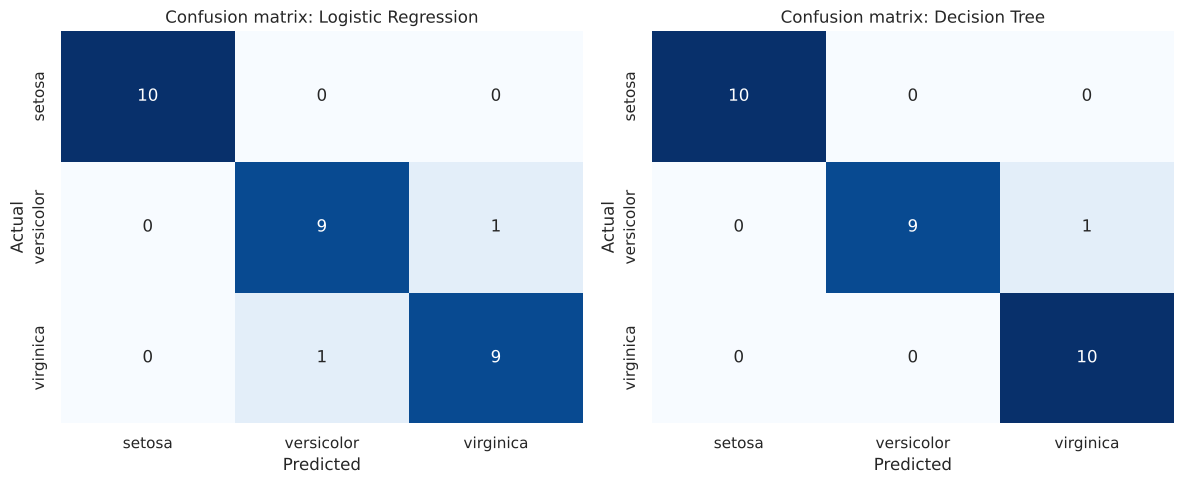

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Confusion matrix: {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 7. Decision boundary visualization

Decision boundaries can only be drawn in 2D, so the models are re-trained on the two most informative features (**petal_length** and **petal_width**). This is for visualization only; the benchmark above uses all four features.

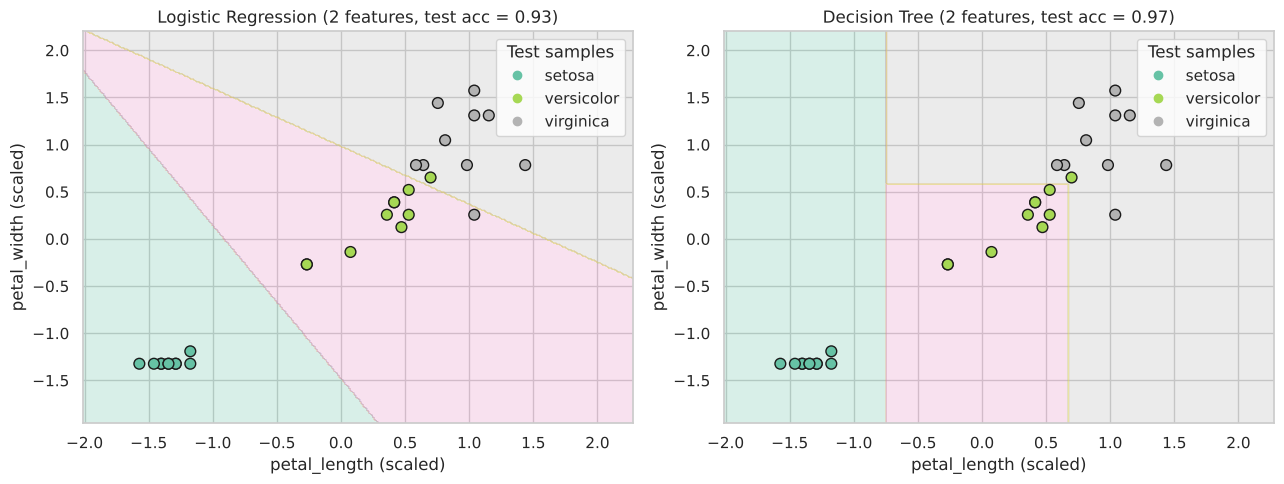

In [9]:
two_feats = ["petal_length", "petal_width"]
X2_train, X2_test = X_train[two_feats], X_test[two_feats]

scaler2 = StandardScaler()
X2_train_s = scaler2.fit_transform(X2_train)
X2_test_s = scaler2.transform(X2_test)

x_min, x_max = X2_train_s[:, 0].min() - 0.5, X2_train_s[:, 0].max() + 0.5
y_min, y_max = X2_train_s[:, 1].min() - 0.5, X2_train_s[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}.items()):
    model.fit(X2_train_s, y_train)
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="Set2")
    scatter = ax.scatter(X2_test_s[:, 0], X2_test_s[:, 1], c=y_test,
                         cmap="Set2", edgecolor="k", s=60)
    acc = accuracy_score(y_test, model.predict(X2_test_s))
    ax.set_title(f"{name} (2 features, test acc = {acc:.2f})")
    ax.set_xlabel(two_feats[0] + " (scaled)")
    ax.set_ylabel(two_feats[1] + " (scaled)")
    ax.legend(handles=scatter.legend_elements()[0], labels=list(class_names), title="Test samples")
plt.tight_layout()
plt.show()

## 8. Conclusion

- Both models perform very well on Iris, a small and well-separated benchmark dataset. In this run the Decision Tree reached 96.7% accuracy and Logistic Regression 93.3%, a difference of a single test sample.
- **Logistic Regression** gives smooth, linear decision boundaries. **Decision Tree** produces axis-aligned, rectangular regions that are easy to interpret but can overfit, so `max_depth` is limited to 3.
- Almost all errors involve *versicolor* and *virginica*, which overlap in feature space (see pairplot and confusion matrices).
- With only 30 test samples, one misclassification changes accuracy by about 3 percentage points. For a more robust comparison, cross-validation would be the next step.